# Satellite covariates — September 2024

This notebook uses the **existing processed satellite datasets** and makes a single, consistent visualisation for **September 2024**:

- SST and SST anomaly
- SSS and SSS anomaly
- MLD and MLD anomaly
- Chl-a and Chl-a anomaly
- cyclical month encodings, `sin(2πm/12)` and `cos(2πm/12)`

The anomaly fields are the anomaly variables already calculated in the satellite preprocessing notebook; no anomaly datasets are created or saved here.


In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

from pathlib import Path

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "figure.titlesize": 16,
})


## Load the existing processed datasets

The paths below should point to the Zarr datasets produced by the existing satellite notebook. Nothing is downloaded or reprocessed here.

In [5]:
# Update these only if your existing processed-data location is different.
DATA_DIR = Path("../data/processed/satellite")

MULTIOBS_PATH = DATA_DIR / "multiobs_1deg_1993_2024.zarr"
CHL_PATH = DATA_DIR / "occii_chl_1deg_1997_2024.zarr"

ds_multi = xr.open_zarr(MULTIOBS_PATH)
ds_chl = xr.open_zarr(CHL_PATH)

print("MULTIOBS variables:", list(ds_multi.data_vars))
print("Chl-a variables:", list(ds_chl.data_vars))
print("MULTIOBS time:", ds_multi.time.min().values, "to", ds_multi.time.max().values)
print("Chl-a time:", ds_chl.time.min().values, "to", ds_chl.time.max().values)


MULTIOBS variables: ['mlotst', 'mlotst_anom', 'mlotst_climatology', 'mlotst_filled_mask', 'mlotst_filled_value', 'mlotst_nan_before_fill', 'sos', 'sos_anom', 'tos', 'tos_anom']
Chl-a variables: ['chlos', 'chlos_anom', 'chlos_climatology', 'chlos_filled_mask', 'chlos_filled_value', 'chlos_nan_before_fill']
MULTIOBS time: 1993-01-01T00:00:00.000000000 to 2024-12-01T00:00:00.000000000
Chl-a time: 1997-09-01T00:00:00.000000000 to 2024-12-01T00:00:00.000000000


In [6]:
# September 2024
TARGET_TIME = "2024-09-01"

multi_sep = ds_multi.sel(time=TARGET_TIME)
chl_sep = ds_chl.sel(time=TARGET_TIME)

print("Selected:", TARGET_TIME)
print("MULTIOBS:", list(multi_sep.data_vars))
print("Chl-a:", list(chl_sep.data_vars))


Selected: 2024-09-01
MULTIOBS: ['mlotst', 'mlotst_anom', 'mlotst_climatology', 'mlotst_filled_mask', 'mlotst_filled_value', 'mlotst_nan_before_fill', 'sos', 'sos_anom', 'tos', 'tos_anom']
Chl-a: ['chlos', 'chlos_anom', 'chlos_climatology', 'chlos_filled_mask', 'chlos_filled_value', 'chlos_nan_before_fill']


## September 2024 maps

Absolute variables use variable-specific sequential colour palettes. Anomalies use a common diverging blue–white–red palette with symmetric limits around zero.

The colourbars are horizontal and use triangular ends (`extend="both"`).

In [7]:
def robust_limits(da, percentile=98, symmetric=False):
    values = np.asarray(da.values)
    values = values[np.isfinite(values)]
    if values.size == 0:
        return 0, 1

    if symmetric:
        lim = np.nanpercentile(np.abs(values), percentile)
        return -lim, lim

    return np.nanpercentile(values, 100 - percentile), np.nanpercentile(values, percentile)


def add_map(ax, da, title, cmap, vmin=None, vmax=None, units="", extend="both"):
    # pcolormesh works directly with the 1° lon/lat grid used by the datasets.
    mesh = da.plot.pcolormesh(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False,
        rasterized=True,
    )

    ax.set_global()
    ax.coastlines(linewidth=0.7)
    ax.add_feature(cfeature.LAND, facecolor="0.88", zorder=2)
    ax.set_title(title, pad=8)

    cb = plt.colorbar(
        mesh,
        ax=ax,
        orientation="horizontal",
        pad=0.055,
        fraction=0.046,
        aspect=28,
        extend=extend,
    )
    cb.set_label(units)
    return mesh


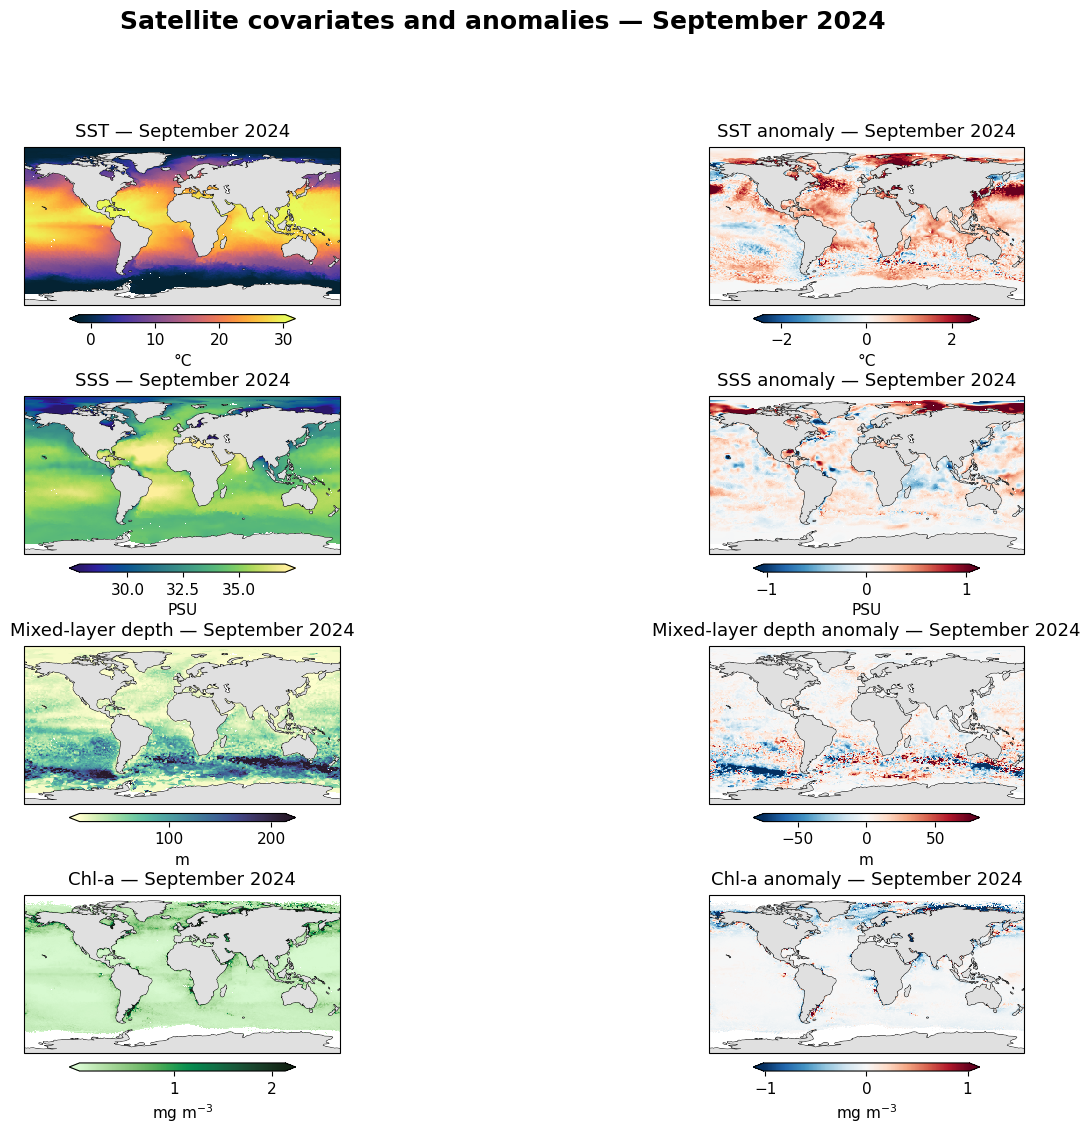

In [8]:
# Variable names in the processed datasets
SPECS = [
    ("tos", "SST", "°C", cmocean.cm.thermal),
    ("sos", "SSS", "PSU", cmocean.cm.haline),
    ("mlotst", "Mixed-layer depth", "m", cmocean.cm.deep),
    ("chlos", "Chl-a", "mg m$^{-3}$", cmocean.cm.algae),
]

ANOM_SPECS = [
    ("tos_anom", "SST anomaly", "°C"),
    ("sos_anom", "SSS anomaly", "PSU"),
    ("mlotst_anom", "Mixed-layer depth anomaly", "m"),
    ("chlos_anom", "Chl-a anomaly", "mg m$^{-3}$"),
]

fig = plt.figure(figsize=(17, 12))
gs = fig.add_gridspec(4, 2, hspace=0.42, wspace=0.08)

for row, (var, name, units, cmap) in enumerate(SPECS):
    ds_here = multi_sep if var != "chlos" else chl_sep
    da = ds_here[var]
    vmin, vmax = robust_limits(da, percentile=98)
    ax = fig.add_subplot(gs[row, 0], projection=ccrs.PlateCarree())
    add_map(ax, da, f"{name} — September 2024", cmap, vmin, vmax, units, extend="both")

    anom_var, anom_name, anom_units = ANOM_SPECS[row]
    da_anom = ds_here[anom_var]
    amin, amax = robust_limits(da_anom, percentile=98, symmetric=True)
    ax = fig.add_subplot(gs[row, 1], projection=ccrs.PlateCarree())
    add_map(ax, da_anom, f"{anom_name} — September 2024", "RdBu_r", amin, amax, anom_units, extend="both")

fig.suptitle("Satellite covariates and anomalies — September 2024", fontsize=18, fontweight="bold", y=0.995)
plt.show()


## Cyclical month encoding

For September, the model's month features are calculated as

$$\sin(2\pi m/12), \qquad \cos(2\pi m/12)$$

using the same month convention as the model. The polar plot makes the cyclic nature of the encoding clear.

In [14]:
month = 9
sin_month = np.sin(2 * np.pi * (month - 1) / 12)
cos_month = np.cos(2 * np.pi * (month - 1) / 12)

print(f"September (m={month})")
print(f"sin(2πm/12) = {sin_month:.4f}")
print(f"cos(2πm/12) = {cos_month:.4f}")


September (m=9)
sin(2πm/12) = -0.8660
cos(2πm/12) = -0.5000


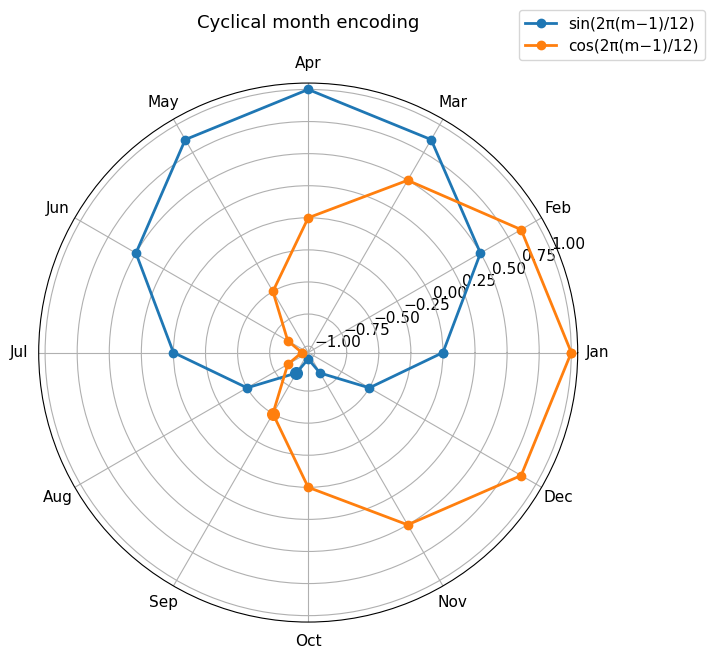

In [16]:
# months = np.arange(1, 13)
# angles = 2 * np.pi * (months - 1) / 12
# sin_vals = np.sin(angles)
# cos_vals = np.cos(angles)

months = np.arange(1, 13)
angles = 2 * np.pi * (months - 1) / 12

# Close the cycle by returning to January
angles_closed = np.append(angles, 2 * np.pi)
sin_vals = np.append(np.sin(angles), np.sin(angles[0]))
cos_vals = np.append(np.cos(angles), np.cos(angles[0]))

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection="polar")

# ax.plot(angles, sin_vals, marker="o", linewidth=2, label="sin(2πm/12)")
# ax.plot(angles, cos_vals, marker="o", linewidth=2, label="cos(2πm/12)")
# ax.plot(angles, sin_vals, marker="o", linewidth=2,
#         label="sin(2π(m-1)/12)")
# ax.plot(angles, cos_vals, marker="o", linewidth=2,
#         label="cos(2π(m-1)/12)")
ax.plot(
    angles_closed,
    sin_vals,
    marker="o",
    linewidth=2,
    label="sin(2π(m−1)/12)"
)

ax.plot(
    angles_closed,
    cos_vals,
    marker="o",
    linewidth=2,
    label="cos(2π(m−1)/12)"
)

# Highlight September without introducing a third colour scheme.
# sep_angle = 2 * np.pi * 9 / 12
sep_angle = 2 * np.pi * (9 - 1) / 12
ax.scatter([sep_angle], [sin_month], s=70, zorder=5)
ax.scatter([sep_angle], [cos_month], s=70, zorder=5)

ax.set_xticks(angles)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylim(-1.05, 1.05)
ax.set_title("Cyclical month encoding", pad=20)
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.15))
plt.show()


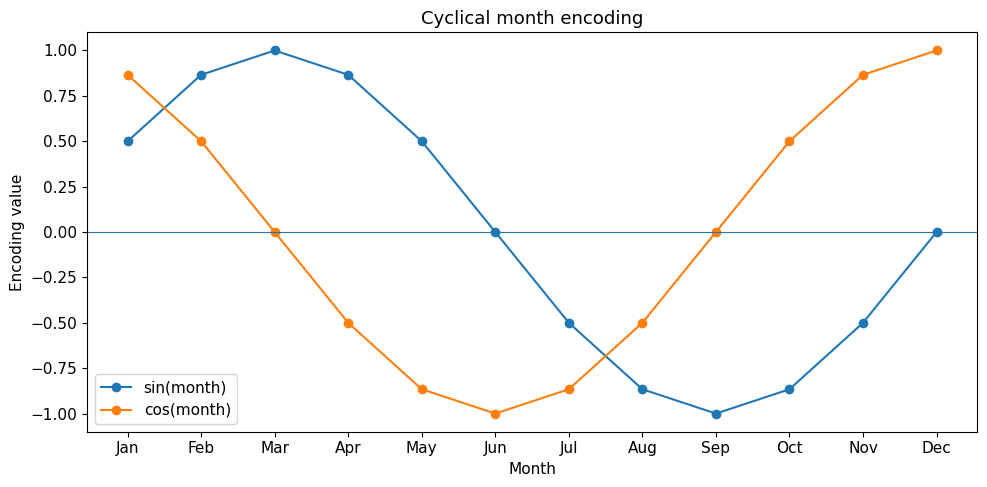

In [18]:
import numpy as np
import matplotlib.pyplot as plt

months = np.arange(1, 13)
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

month_sin = np.sin(2 * np.pi * months / 12)
month_cos = np.cos(2 * np.pi * months / 12)

plt.figure(figsize=(10, 5))

plt.plot(month_labels, month_sin, marker="o", label="sin(month)")
plt.plot(month_labels, month_cos, marker="o", label="cos(month)")

plt.axhline(0, linewidth=0.8)
plt.xlabel("Month")
plt.ylabel("Encoding value")
plt.title("Cyclical month encoding")
plt.ylim(-1.1, 1.1)
plt.legend()
# plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### September values

For September 2024, the two cyclical features are approximately:

- `sin(2πm/12) = -1.000`
- `cos(2πm/12) = -0.000`

These two values encode the month continuously on a circle rather than treating month 12 and month 1 as distant categories.